<a href="https://colab.research.google.com/github/cocoaperson/python-lab1-data-cleaning/blob/main/notebooks/03_colab_executed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Colab
Этот шаблон нужно выполнить в реальном сеансе Colab. Локальное исполнение не выдаётся за облачное. Загрузите data/interim/sample.csv, затем Run all. Откройте доступ Anyone with the link и сохраните копию в GitHub.

## Версия интерпретатора

In [1]:
import sys
print(sys.version)
print("Требуемая версия: 3.12.14")
print("Совпадает:", sys.version_info[:3] == (3,12,14))

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Требуемая версия: 3.12.14
Совпадает: False


## Библиотеки

In [2]:
!pip install pandas==3.0.6 polars==2.0.0
import pandas as pd
import polars as pl
print("pandas", pd.__version__, "polars", pl.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 11.0 MB/s eta 0:00:00
  Attempting uninstall: polars-runtime-32
    Found existing installation: polars-runtime-32 1.35.2
    Uninstalling polars-runtime-32-1.35.2:
      Successfully uninstalled polars-runtime-32-1.35.2
  Attempting uninstall: polars
    Found existing installation: polars 1.35.2
    Uninstalling polars-1.35.2:
      Successfully uninstalled polars-1.35.2
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.


## Загрузка отладочного среза

In [3]:
from google.colab import files
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)
print(df.shape)
display(df.head())

Saving sample.csv to sample.csv
(200000, 33)


,id,type,language,license,rightsHolder,accessRights,datasetID,institutionCode,datasetName,ownerInstitutionCode,...,decimalLatitude,decimalLongitude,geodeticDatum,coordinateUncertaintyInMeters,georeferenceSources,georeferenceVerificationStatus,scientificName,kingdom,taxonRank,vernacularName
0,801:20130517200539,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233483,2.930108,WGS84,6,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
1,801:20130517223523,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233446,2.930020,WGS84,14,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
2,801:20130518033642,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233514,2.930039,WGS84,14,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
3,801:20130518064136,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.238040,2.922763,WGS84,15,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
4,801:20130518091123,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233480,2.930142,WGS84,12,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull


## Типы и пропуски

In [4]:
display(pd.DataFrame({"тип":df.dtypes.astype(str), "пропусков":df.isna().sum(), "доля":df.isna().mean()}))

,тип,пропусков,доля
id,str,0,0.0
type,str,0,0.0
language,str,0,0.0
license,str,0,0.0
rightsHolder,str,0,0.0
accessRights,str,0,0.0
datasetID,str,0,0.0
institutionCode,str,0,0.0
datasetName,str,0,0.0
ownerInstitutionCode,str,0,0.0


## Наблюдения по годам
Первые 200 тысяч строк предназначены для отладки, их временное распределение не представляет всю базу.

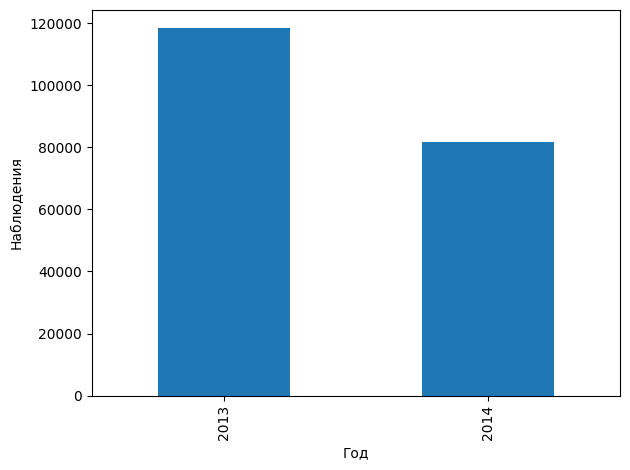

In [5]:
import matplotlib.pyplot as plt
years=pd.to_datetime(df.eventDate,utc=True).dt.year.value_counts().sort_index()
years.plot.bar()
plt.xlabel("Год"); plt.ylabel("Наблюдения"); plt.tight_layout(); plt.show()